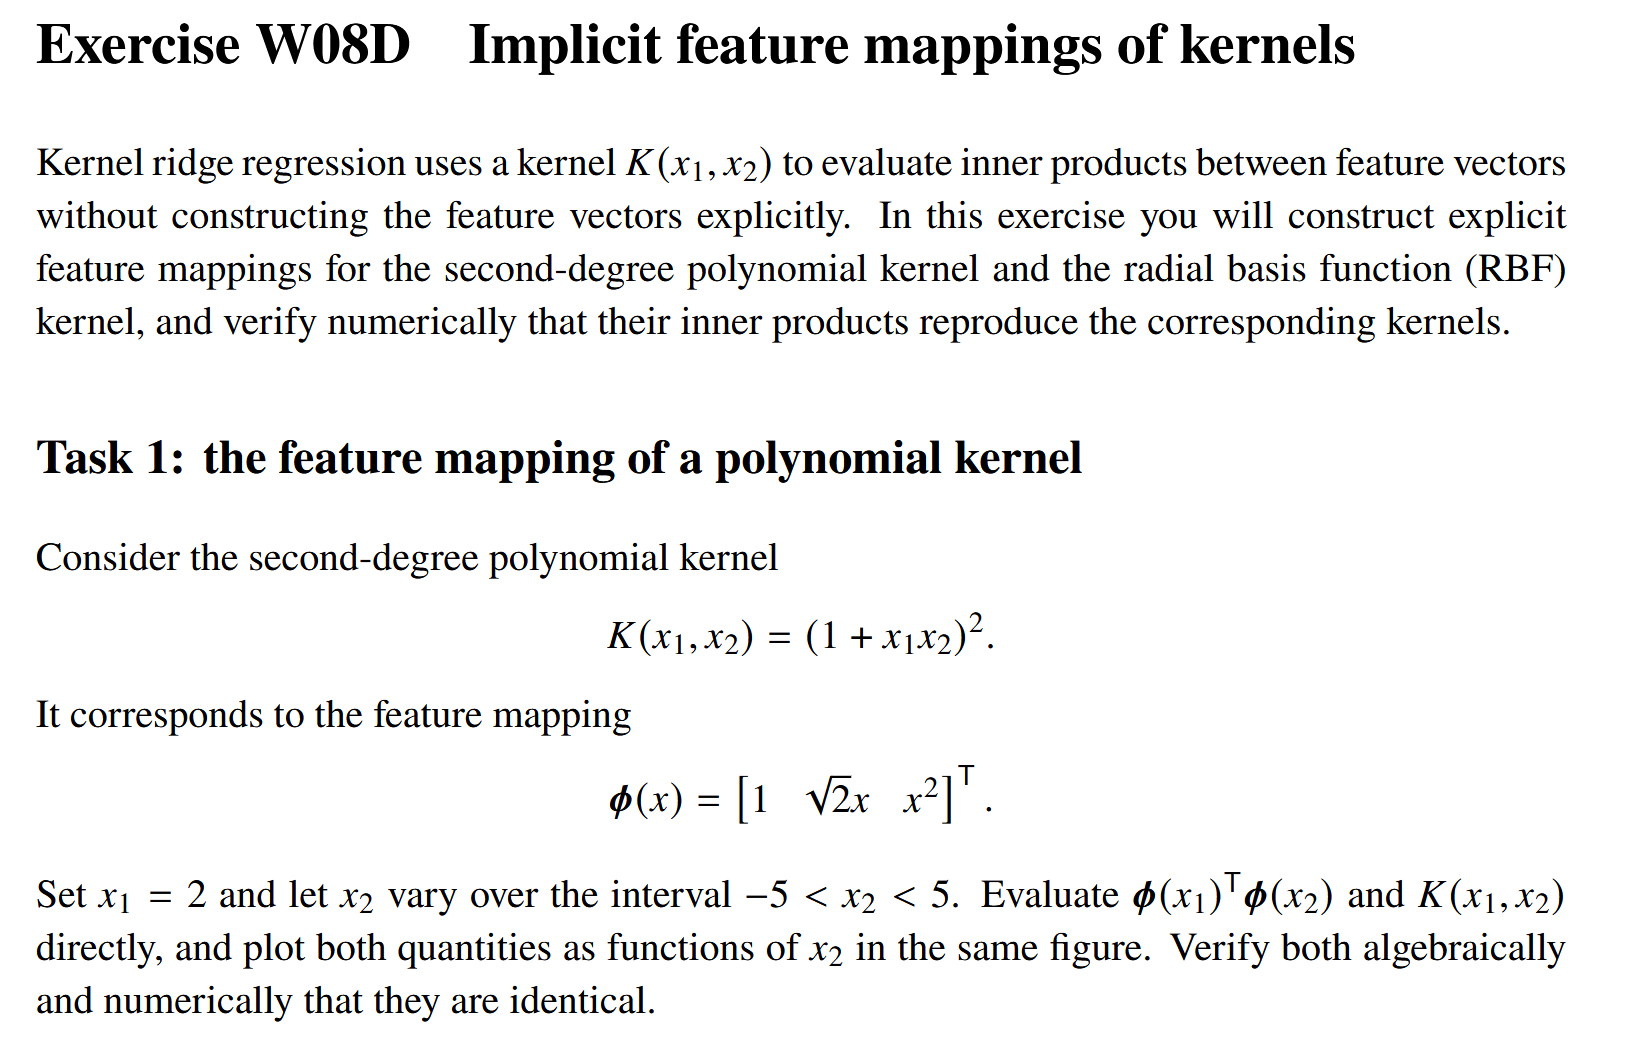

Text(0.5, 0, 'x2')

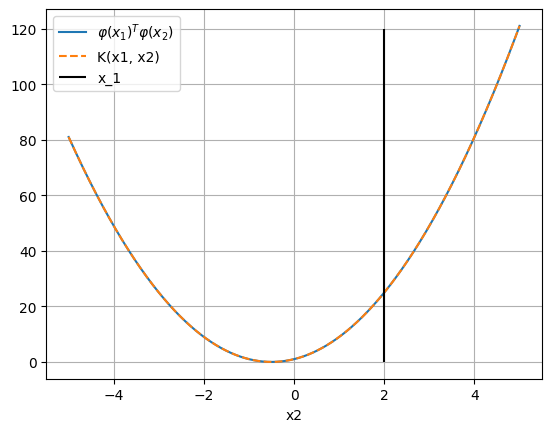

In [43]:
import numpy as np 
import matplotlib.pyplot as plt 
from Regression import *

class KernalRidgeRegression(KernalRidgeRegression):
    def K(self, x1, x2):
        return (1 + x1*x2)**2

krr = KernalRidgeRegression(1, 1)

def phi(x):
    return np.array([np.ones_like(x), np.sqrt(2)*x, x**2])

x1 = 2
x2 = np.linspace(-5, 5, 1000)

fig, ax = plt.subplots(1, 1)

ax.plot(x2, phi(x1) @ phi(x2), label=r'$φ(x_1)^Tφ(x_2)$')
ax.plot(x2, krr.K(x1, x2), '--', label='K(x1, x2)')
ax.vlines(2.0, 0, 120, color='black', label=r'x_1')
ax.legend()
ax.grid()
ax.set_xlabel('x2')


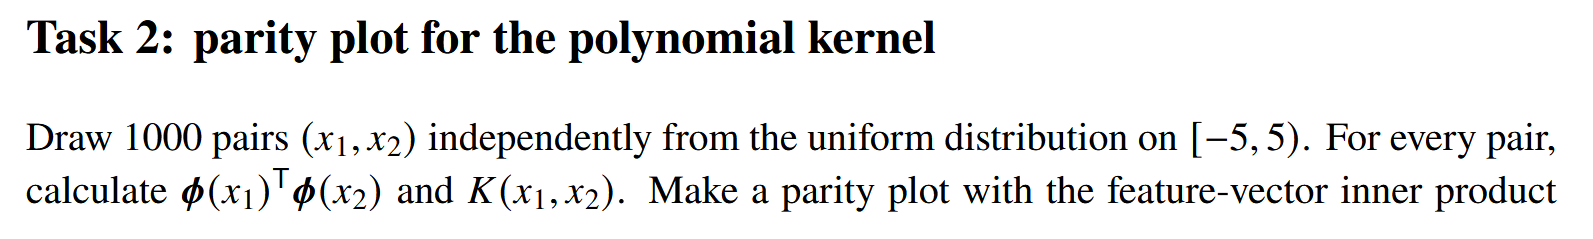
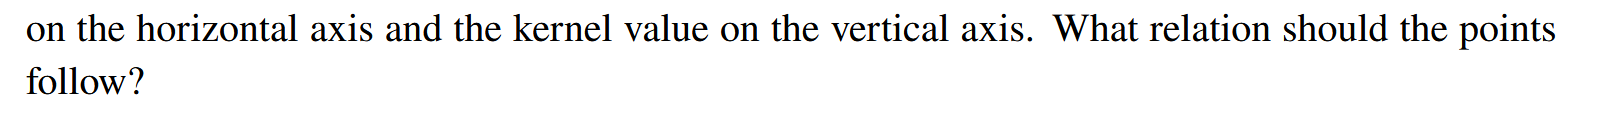

The parity plot will show a perfect diagonal line representing the equation $y = x$.

**What this shows**

* The plot maps the explicitly calculated inner product $\phi(x_1)^T \phi(x_2)$ on the horizontal axis and the shortcut kernel value $K(x_1, x_2)$ on the vertical axis.


* Because the feature mapping and the kernel function are mathematically equivalent for this polynomial, every single one of the 1000 randomly drawn pairs will produce identical values for both calculations, causing all points to land exactly on the 1:1 identity line.



**Why we do it**

* **Global Empirical Proof:** While the previous task checked the relationship against a single fixed point ($x_1 = 2$), drawing 1000 independent random pairs from the uniform distribution numerically proves that the equivalence holds everywhere across the entire $[-5, 5)$ domain.


* **Demonstrating the Kernel Trick:** It serves as a visual confirmation of why the "kernel trick" is so powerful. It proves that you can entirely skip the process of projecting data into higher dimensions explicitly ($\phi$) and instead use the computationally cheaper kernel function ($K$) to get the exact same inner product.

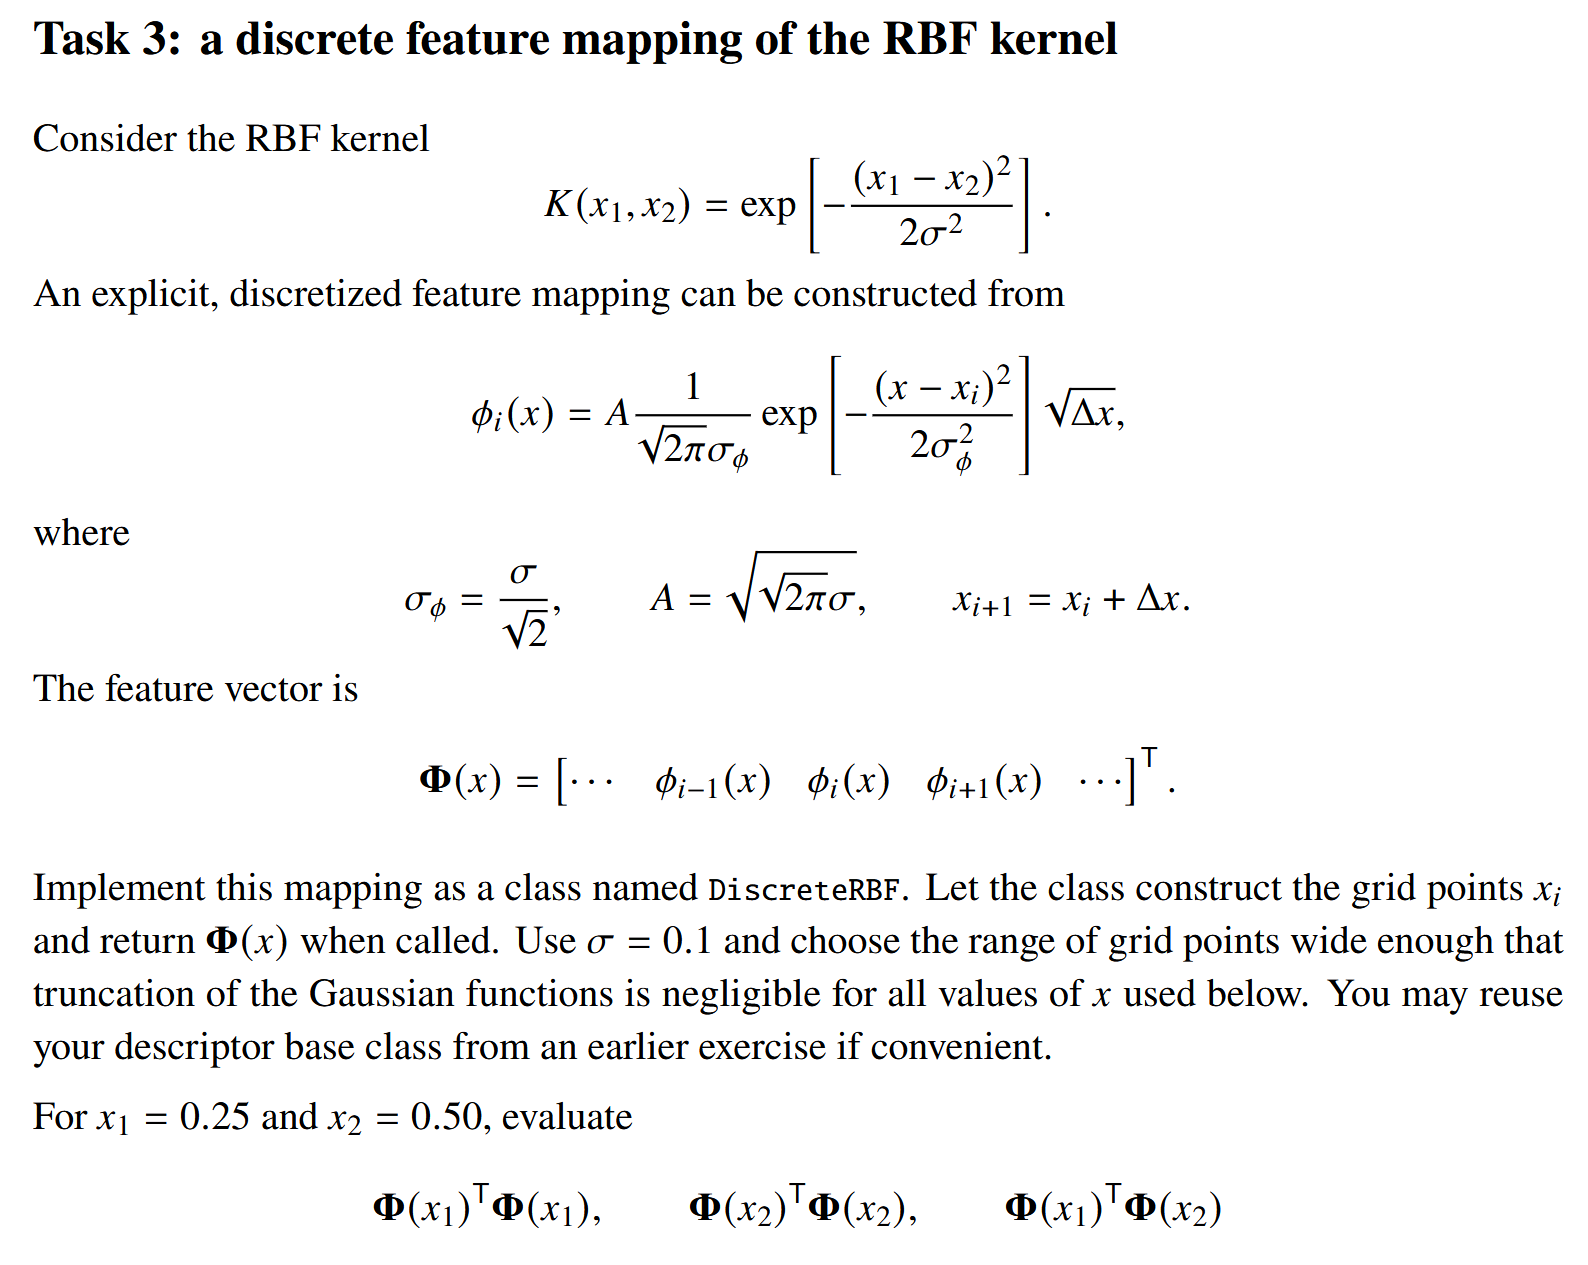
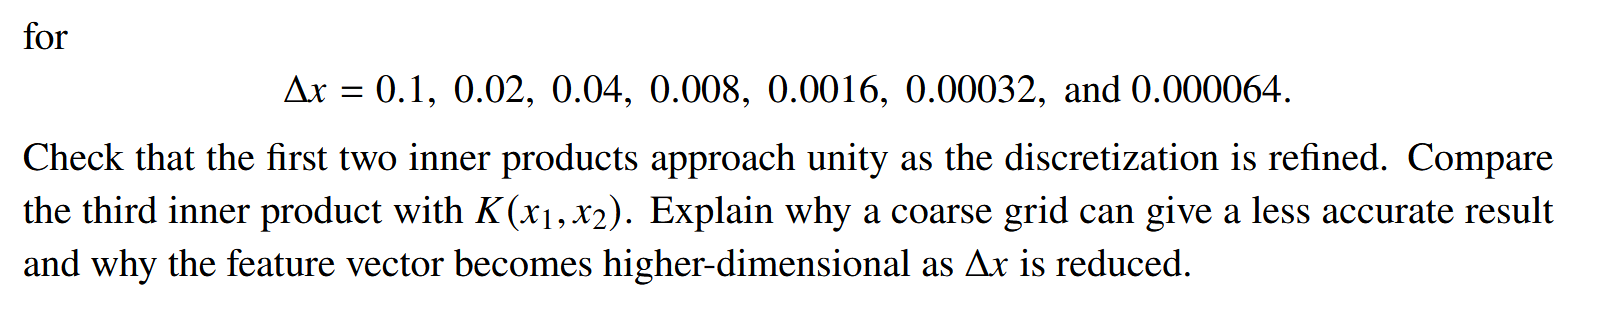

In [44]:
class DiscreteRBF:
    def __init__(self, σ, dx, xmin=-1.0, xmax=2.0):
        self.s = σ
        self.dx = dx

        self.xi = np.arange(xmin, xmax + dx, dx)

        self.sig_phi = self.s/np.sqrt(2)
        self.A = np.sqrt(np.sqrt(2*np.pi) * self.s)

    def __call__(self, x): # φ_i(x)
        normalization = 1 / (np.sqrt(2 * np.pi) * self.sig_phi)
        exponent = np.exp(-((x - self.xi)**2) / (2 * self.sig_phi**2))
        return self.A * normalization * exponent * np.sqrt(self.dx)

def exact_K(x1, x2, sigma):
    return np.exp(-((x1 - x2)**2) / (2 * sigma**2))

# Parameters
sigma = 0.1
x1 = 0.25
x2 = 0.50
dx_values = [0.1, 0.02, 0.04, 0.008, 0.0016, 0.00032, 0.000064]

print(f"{'dx':<10} | {'Phi(x1).T @ Phi(x1)':<22} | {'Phi(x2).T @ Phi(x2)':<22} | {'Phi(x1).T @ Phi(x2)':<22}")
print("-" * 82)

for dx in dx_values:
    # Initialize the mapping for the current dx
    phi_map = DiscreteRBF(σ=sigma, dx=dx)
    
    # Get feature vectors
    Phi_x1 = phi_map(x1)
    Phi_x2 = phi_map(x2)
    
    # Calculate inner products
    inner_11 = np.dot(Phi_x1, Phi_x1)
    inner_22 = np.dot(Phi_x2, Phi_x2)
    inner_12 = np.dot(Phi_x1, Phi_x2)
    
    print(f"{dx:<10} | {inner_11:<22.6f} | {inner_22:<22.6f} | {inner_12:<22.6f}")

print("-" * 82)
print(f"Exact K(x1, x2): {exact_K(x1, x2, sigma):.6f}")

dx         | Phi(x1).T @ Phi(x1)    | Phi(x2).T @ Phi(x2)    | Phi(x1).T @ Phi(x2)   
----------------------------------------------------------------------------------
0.1        | 0.985616               | 1.014384               | 0.043937              
0.02       | 1.000000               | 1.000000               | 0.043937              
0.04       | 1.000000               | 1.000000               | 0.043937              
0.008      | 1.000000               | 1.000000               | 0.043937              
0.0016     | 1.000000               | 1.000000               | 0.043937              
0.00032    | 1.000000               | 1.000000               | 0.043937              
6.4e-05    | 1.000000               | 1.000000               | 0.043937              
----------------------------------------------------------------------------------
Exact K(x1, x2): 0.043937


### Explanations

* **Convergence to Unity:** As the discretization is refined (smaller $\Delta x$), the first two inner products ($\Phi(x_1)^T\Phi(x_1)$ and $\Phi(x_2)^T\Phi(x_2)$) approach exactly 1.0. This occurs because the exact continuous RBF kernel evaluates to $K(x,x) = \exp(0) = 1$, and the discrete mapping acts as a Riemann sum approximation of the underlying continuous integral.


* **Comparison of the Third Inner Product:** As $\Delta x$ decreases, the third inner product ($\Phi(x_1)^T\Phi(x_2)$) accurately converges to the exact analytical value of $K(x_1, x_2)$.


* **Inaccuracy of a Coarse Grid:** A coarse grid (large $\Delta x$) evaluates the Gaussian basis functions at widely spaced intervals, resulting in a poor discrete approximation of the continuous function. This large step size causes the numerical integration (the dot product) to miss the rapidly changing curves of the Gaussian, introducing high discretization error.


* **Higher Dimensionality:** The feature vector $\Phi(x)$ is constructed such that each element corresponds to a specific grid point $x_i$. When $\Delta x$ is reduced to refine the grid, more grid points $x_i$ are generated to cover the same spatial domain, directly increasing the number of elements (dimensions) in the resulting feature vector.

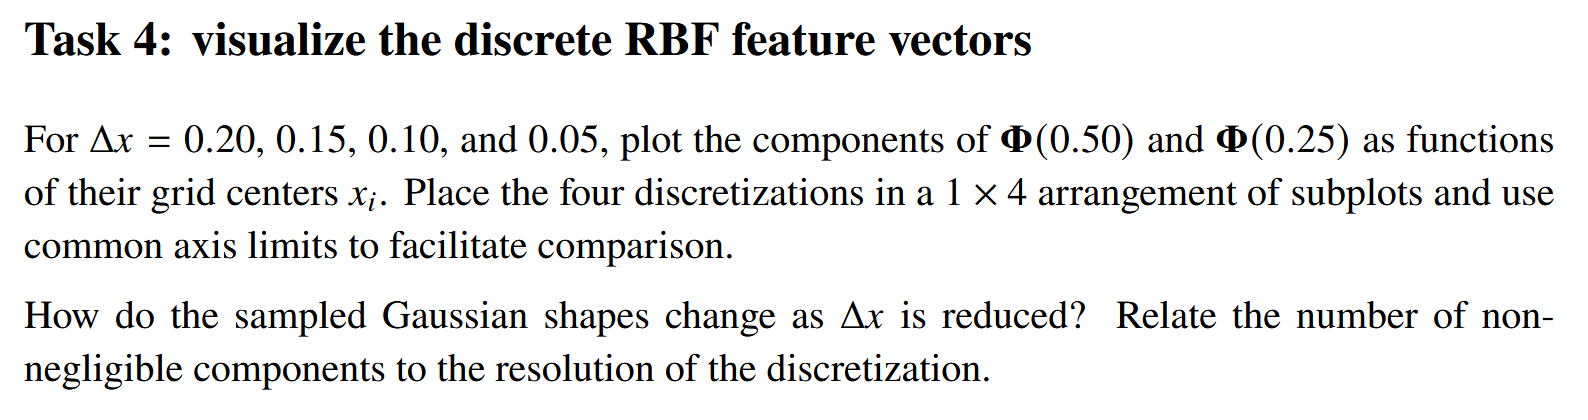

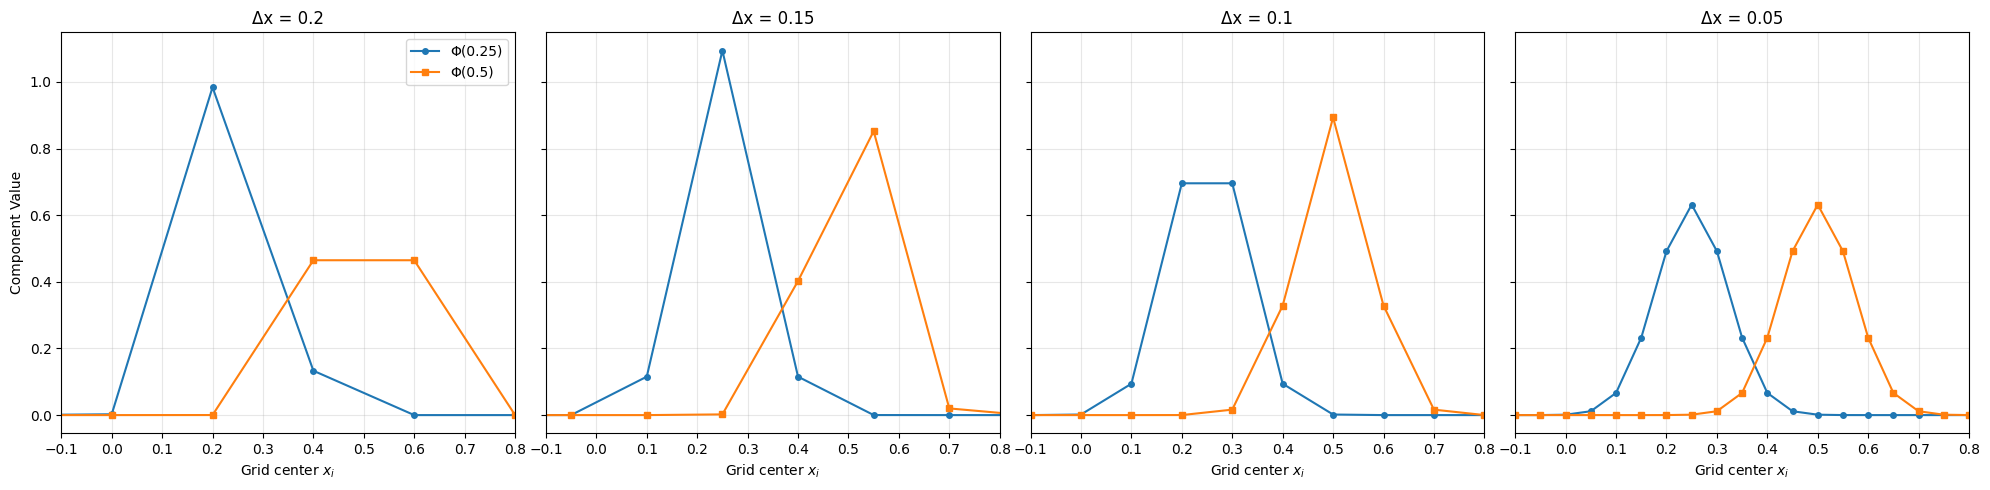

In [45]:
dx_values = [0.20, 0.15, 0.10, 0.05]
sigma = 0.1
x1 = 0.25
x2 = 0.50

fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True, sharex=True)

for ax, dx in zip(axes, dx_values):
    rbf = DiscreteRBF(sigma, dx=dx, xmin=-0.2, xmax=1.0)
    
    # Calculate feature vectors
    phi_x1 = rbf(x1)
    phi_x2 = rbf(x2)
    xi = rbf.xi
    
    # Plot components as functions of their grid centers xi
    ax.plot(xi, phi_x1, marker='o', markersize=4, linestyle='-', label=f'Φ({x1})')
    ax.plot(xi, phi_x2, marker='s', markersize=4, linestyle='-', label=f'Φ({x2})')
    
    ax.set_title(f'Δx = {dx}')
    ax.set_xlabel(r'Grid center $x_i$')
    ax.grid(True, alpha=0.3)

axes[0].set_xlim(-0.1, 0.8)
axes[0].set_ylabel('Component Value')
axes[0].legend()

plt.tight_layout()
plt.show()

### Explanations

* **Number of non-negligible components:** The spatial footprint where the Gaussian curve has non-zero values is fixed by $\sigma$. As the resolution becomes finer (a smaller $\Delta x$), more discrete grid points $x_i$ fit into that fixed spatial footprint. Consequently, the number of non-negligible components in the feature vector increases inversely proportional to the reduction in $\Delta x$.

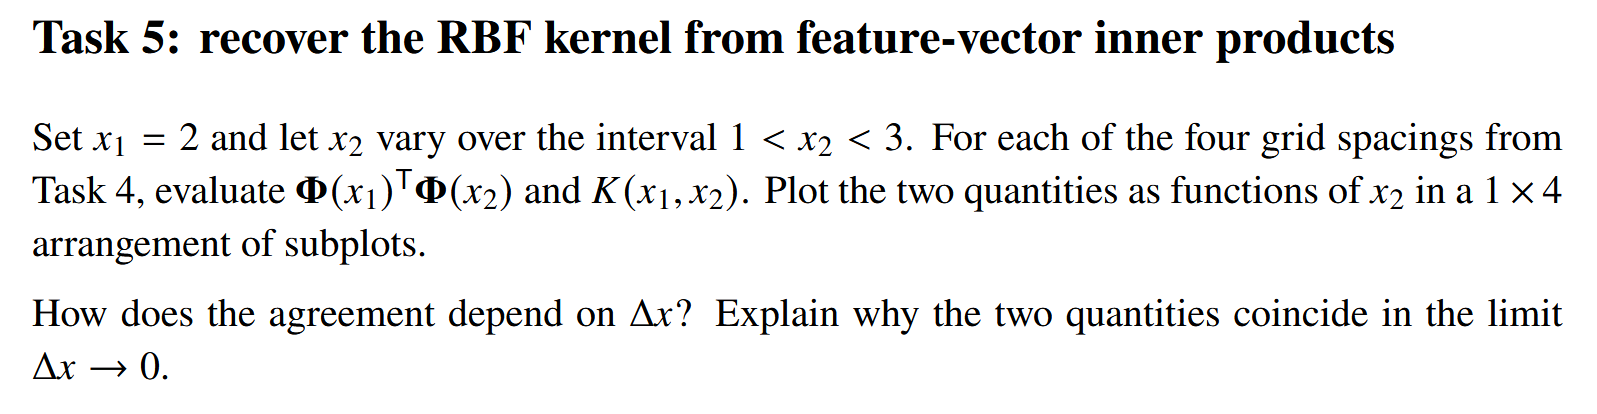

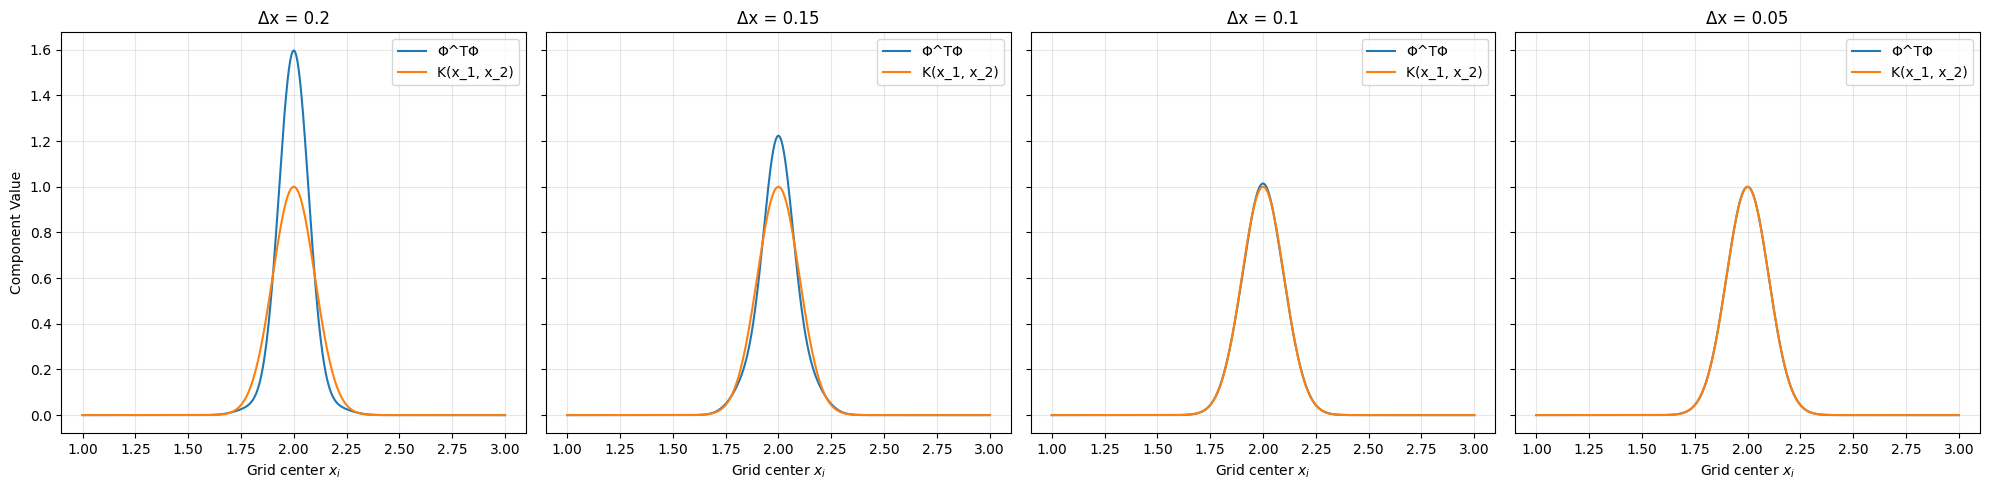

In [46]:
x2_lin = np.linspace(1, 3, 1000)
x1 = 2.0

fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True, sharex=True)

for ax, dx in zip(axes, dx_values):
    rbf = DiscreteRBF(sigma, dx=dx, xmin=-1.0, xmax=5.0)
    
    pp = [rbf(x1) @ rbf(x2) for x2 in x2_lin]
    K = exact_K(x1, x2_lin, sigma)
    
    # Plot components as functions of their grid centers xi
    ax.plot(x2_lin, pp, label=r'Φ^TΦ')
    ax.plot(x2_lin, K,  label=r'K(x_1, x_2)')
    
    ax.set_title(f'Δx = {dx}')
    ax.set_xlabel(r'Grid center $x_i$')
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[0].set_ylabel('Component Value')

plt.tight_layout()
plt.show()

### Explanations

* **How the agreement depends on $\Delta x$:** The agreement between the explicit inner product and the exact kernel improves significantly as $\Delta x$ decreases. For a coarse grid like $\Delta x = 0.20$, there is a visible mismatch (discretization error) between the two curves, but for a finer grid like $\Delta x = 0.05$, the two curves overlap almost perfectly.


* **Limit $\Delta x \rightarrow 0$:** The discrete feature mapping $\Phi(x)$ is formulated as a Riemann sum that approximates a continuous Gaussian integral. As the grid spacing $\Delta x$ approaches zero, the Riemann sum perfectly converges to the exact continuous integral, meaning the inner product mathematically becomes identical to the exact RBF kernel.

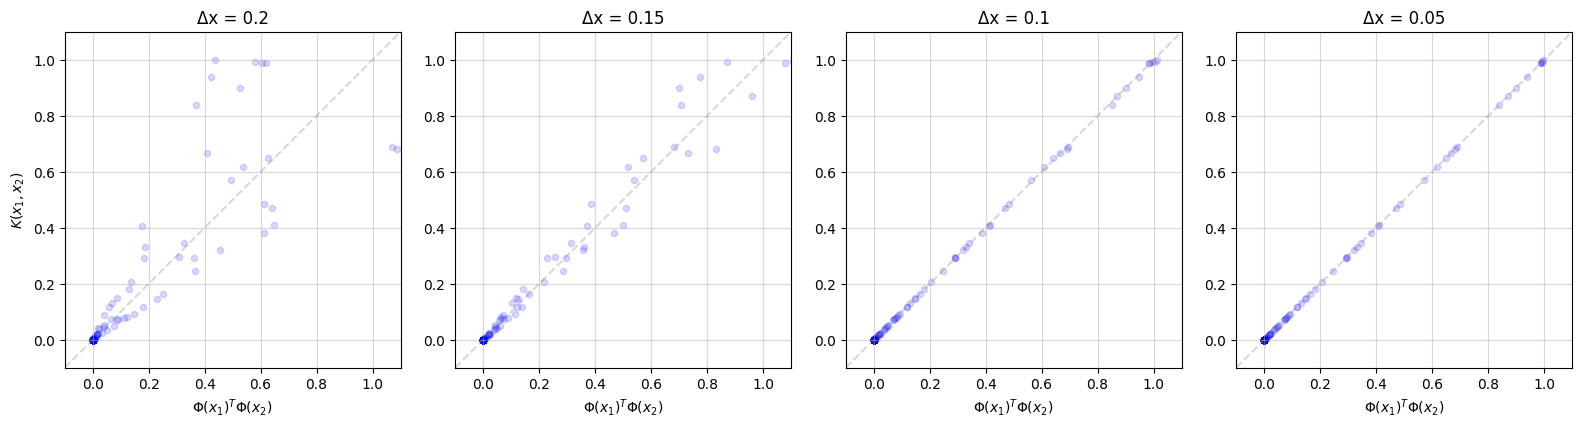

In [51]:
x1_rand = np.random.uniform(-5, 5, 1000)
x2_rand = np.random.uniform(-5, 5, 1000)

dx_values = [0.20, 0.15, 0.10, 0.05]
sigma = 0.1

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, dx in zip(axes, dx_values):
    rbf = DiscreteRBF(σ=sigma, dx=dx, xmin=-6.0, xmax=6.0)
    
    phi_x1 = np.array([rbf(x1) for x1 in x1_rand])
    phi_x2 = np.array([rbf(x2) for x2 in x2_rand])

    inner_products = np.sum(phi_x1 * phi_x2, axis=1)
    
    k_exact = exact_K(x1_rand, x2_rand, sigma)
    
    ax.scatter(inner_products, k_exact, alpha=0.15, color='blue', s=20)
    
    ax.plot([-0.1, 1.1], [-0.1, 1.1], color='gray', linestyle='--', alpha=0.3)
    
    ax.set_title(f'Δx = {dx}')
    ax.set_xlabel(r'$Φ(x_1)^T Φ(x_2)$')
        
    ax.set_xlim(-0.1, 1.1)
    ax.set_ylim(-0.1, 1.1)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.5)

axes[0].set_ylabel(r'$K(x_1, x_2)$')
plt.tight_layout()
plt.show()